# 노년층 발화 기반 감정 분류 모델

## 1. 데이터 탐색 (EDA)

### 데이터셋 정보
- 데이터셋명: 노년층 대상 감성 분류 모델
- 출처: AI Hub
- URL: https://aihub.or.kr/aihubdata/data/view.do?dataSetSn=453
- 데이터 구성: Train 10,150개, Test 1,276개
- 감정 클래스: 기쁨, 당황, 분노, 불안, 상처, 슬픔

### 데이터셋 선정 이유
최근 심리 분야에 관심이 생겨 인간의 발화 텍스트를 기반으로 감정을 분류하는 모델을 구현하고 싶었다.
관련 데이터셋을 탐색하던 중 노년층의 발화와 감정 레이블이 포함된 데이터셋을 발견하였다. 노년층의 감정을 자동으로 분류하는 기술이 노인 돌봄 및 정서 지원 서비스에 활용될 수 있다고 생각하여 해당 데이터셋을 선정하였다.
또한 발화 텍스트와 감정 레이블이 함께 제공되므로 지도학습 기반의 다중 클래스 분류 모델을 구현하기에 적합하다고 판단하였다.

### 프로젝트 목적
Logistic Regression과 Linear SVM의 감정 분류 성능을 비교하고,
최적의 모델을 활용하여 사용자 입력 문장의 감정을 예측하는 웹 서비스를 구현한다.

In [35]:
import pandas as pd
import matplotlib.pyplot as plt
import re

from sklearn.model_selection import train_test_split

train = pd.read_csv("data/train.csv")
test = pd.read_csv("data/test.csv")

print("Train:", train.shape)
print("Test:", test.shape)

# train.head()

Train: (10150, 10)
Test: (1276, 10)


### 1.1 데이터 구조 및 결측치 확인

데이터의 컬럼 구성, 결측치 및 중복 여부를 확인하여
모델 학습에 필요한 특징과 전처리 방법을 결정한다.

In [36]:
train.info()

display(pd.DataFrame({
    "Train 결측치": train.isna().sum(),
    "Test 결측치": test.isna().sum()
}))

print("Train 중복 행:", train.duplicated().sum())
print("Test 중복 행:", test.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10150 entries, 0 to 10149
Data columns (total 10 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   성별      10150 non-null  object
 1   감정_대분류  10150 non-null  object
 2   사람문장1   10150 non-null  object
 3   시스템응답1  10150 non-null  object
 4   사람문장2   10150 non-null  object
 5   시스템응답2  10150 non-null  object
 6   사람문장3   8342 non-null   object
 7   시스템응답3  8342 non-null   object
 8   사람문장4   365 non-null    object
 9   시스템응답4  331 non-null    object
dtypes: object(10)
memory usage: 793.1+ KB


,Train 결측치,Test 결측치
ID,NaN,0.0
감정_대분류,0.0,NaN
사람문장1,0.0,0.0
사람문장2,0.0,0.0
사람문장3,1808.0,238.0
사람문장4,9785.0,1227.0
성별,0.0,0.0
시스템응답1,0.0,0.0
시스템응답2,0.0,0.0
시스템응답3,1808.0,238.0


Train 중복 행: 0
Test 중복 행: 0


### 1.2 감정 클래스 분포 확인

감정 클래스별 데이터 개수와 비율을 확인하여
클래스 불균형 여부 및 데이터 분량 조절의 필요성을 판단한다.

,개수,비율(%)
감정_대분류,,
불안,1818,17.91
슬픔,1749,17.23
기쁨,1716,16.91
상처,1631,16.07
분노,1623,15.99
당황,1613,15.89


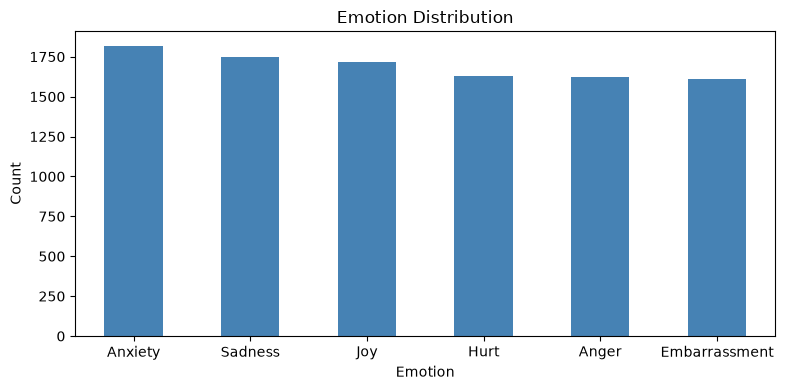

In [37]:
emotion_counts = train["감정_대분류"].value_counts()

display(pd.DataFrame({
    "개수": emotion_counts,
    "비율(%)": (emotion_counts / len(train) * 100).round(2)
}))

emotion_names = {
    "기쁨": "Joy",
    "당황": "Embarrassment",
    "분노": "Anger",
    "불안": "Anxiety",
    "상처": "Hurt",
    "슬픔": "Sadness"
}

emotion_counts.rename(index=emotion_names).plot(
    kind="bar", figsize=(8, 4), color="steelblue"
)

plt.title("Emotion Distribution")
plt.xlabel("Emotion")
plt.ylabel("Count")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig("images/emotion_distribution.png",
            dpi=200, bbox_inches="tight")
plt.show()

### 1.3 데이터 탐색 결과

- 사람문장3~4에 결측치가 존재하므로 결측 문장만 제외하고 유효한 발화를 활용한다.
- 감정 클래스별 데이터 분포가 비교적 균등하므로 별도의 오버샘플링 및 언더샘플링을 수행하지 않는다.
- 사람의 발화 텍스트를 입력 특징으로, 감정_대분류를 목표 변수로 사용한다.

## 2. 데이터 전처리 (Preprocessing)

### 2.1 전처리 절차 및 선정 이유

1. 특징 선정: 사람문장1~4를 입력 특징으로, 감정_대분류를 목표 변수로 설정한다.
   사람의 발화 자체에서 감정을 분류하기 위해 성별과 시스템 응답은 제외한다.

2. 결측치 처리: 행 전체를 삭제하면 데이터 손실이 발생하므로 결측 문장만 제외한다.

3. 문장 결합: 여러 발화에 나타나는 감정 정보를 함께 활용하기 위해 하나의 텍스트로 결합한다.

4. 텍스트 정제: 정규표현식을 이용하여 연속 공백, 줄바꿈, 탭을 정리한다.
   감정 표현의 손실을 방지하기 위해 불용어 및 특수문자 제거는 수행하지 않는다.

5. 데이터 분량 조절: 클래스 분포가 비교적 균등하므로 별도의 데이터 증감 없이 전체 데이터를 활용한다.

학습 데이터와 테스트 데이터에 동일한 전처리 방법을 적용한다.

In [38]:
person_cols = ["사람문장1", "사람문장2", "사람문장3", "사람문장4"]

# 결측 문장 제외 및 문장 결합
def combine_person_sentences(row):
    sentences = [
        str(row[col]) for col in person_cols
        if pd.notna(row[col])
    ]
    return " ".join(sentences)

# 불필요한 공백 제거
def clean_text(text):
    return re.sub(r"\s+", " ", text).strip()

# 동일한 전처리 적용
for df in [train, test]:
    df["text"] = df.apply(combine_person_sentences, axis=1)
    df["text"] = df["text"].apply(clean_text)

# train[["text", "감정_대분류"]].head()
print("텍스트 전처리 완료")

텍스트 전처리 완료


In [39]:
# 전처리 결과 검증
for name, df in [("Train", train), ("Test", test)]:
    print(f"=== {name} ===")
    print("데이터 개수:", len(df))
    print("텍스트 결측치:", df["text"].isna().sum())
    print("빈 문자열:", df["text"].eq("").sum())

print("감정 레이블 결측치:", train["감정_대분류"].isna().sum())

=== Train ===
데이터 개수: 10150
텍스트 결측치: 0
빈 문자열: 0
=== Test ===
데이터 개수: 1276
텍스트 결측치: 0
빈 문자열: 0
감정 레이블 결측치: 0


### 2.2 학습 및 검증 데이터 분할

모델의 일반화 성능을 평가하기 위해 학습 데이터를 8:2 비율로 분할한다.
80%를 학습에 활용하여 충분한 학습량을 확보하고, 20%를 성능 검증에 활용한다.

- test_size=0.2: 검증 데이터 비율 20%
- random_state=42: 동일한 데이터 분할 결과를 얻기 위한 난수 고정
- stratify=y: 분할 전후 감정 클래스 비율 유지

별도로 제공된 Test 데이터는 실제 감정 레이블이 없으므로 최종 예측에 활용한다.

In [40]:
X = train["text"]
y = train["감정_대분류"]

X_train, X_valid, y_train, y_valid = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Train:", len(X_train))
print("Validation:", len(X_valid))
print("Test:", len(test))

# 분할 전후 클래스 비율 비교
display(pd.DataFrame({
    "전체(%)": y.value_counts(normalize=True) * 100,
    "학습(%)": y_train.value_counts(normalize=True) * 100,
    "검증(%)": y_valid.value_counts(normalize=True) * 100
}).round(2))

Train: 8120
Validation: 2030
Test: 1276


,전체(%),학습(%),검증(%)
감정_대분류,,,
불안,17.91,17.91,17.93
슬픔,17.23,17.23,17.24
기쁨,16.91,16.91,16.90
상처,16.07,16.07,16.06
분노,15.99,16.00,15.96
당황,15.89,15.89,15.91


### 2.3 전처리 결과

결측 문장 제외, 문장 결합 및 텍스트 정제를 수행하였다.
전체 학습 데이터 10,150개를 학습용 8,120개와 검증용 2,030개로 분할하였으며,
별도 테스트 데이터 1,276개에도 동일한 텍스트 전처리를 적용하였다.

텍스트의 수치 벡터화는 데이터 누출을 방지하기 위해
모델 학습 단계에서 TF-IDF와 Pipeline을 이용하여 수행한다.

## 3. 모델 학습 (Modeling)

### 3.1 특징 벡터화: TF-IDF

기계학습 모델은 텍스트를 직접 처리할 수 없으므로 TF-IDF를 이용하여
발화 문장을 수치 벡터로 변환한다.

TF-IDF는 특정 문서에서 자주 등장하면서 전체 문서에서는
상대적으로 적게 등장하는 단어에 높은 가중치를 부여한다.

#### 파라미터 선정 이유
- max_features=20000: 특징 수를 제한하여 연산량과 메모리 사용량을 줄인다.
- ngram_range=(1, 2): 단일 단어뿐만 아니라 연속된 두 단어의 표현도 반영한다.
- min_df=2: 한 문서에만 등장하는 희소한 특징을 제외한다.

### 3.2 학습 알고리즘 선정

- Logistic Regression: 다중 클래스 분류에 활용할 수 있으며,
  학습 속도가 빠르고 고차원 텍스트 데이터에 적용하기 적합하여
  성능 비교의 기준 모델로 선정하였다.

- Linear SVM: 클래스 간 마진을 최대화하는 분류 알고리즘으로,
  TF-IDF와 같은 고차원 희소 벡터의 분류에 적합하여 선정하였다.

### 3.3 Pipeline 구성

TF-IDF와 분류 모델을 하나의 Pipeline으로 구성한다.
학습 데이터에 대해서만 TF-IDF를 학습하여 데이터 누출을 방지하고,
검증 및 테스트 데이터에도 동일한 벡터화 과정을 적용한다.

두 모델에 동일한 TF-IDF 설정을 적용하여 알고리즘별 성능을 비교한다.

In [41]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline

tfidf_params = {
    "max_features": 20000,
    "ngram_range": (1, 2),
    "min_df": 2
}

# Logistic Regression
lr_model = Pipeline([
    ("tfidf", TfidfVectorizer(**tfidf_params)),
    ("clf", LogisticRegression(max_iter=1000))
])

# Linear SVM
svm_model = Pipeline([
    ("tfidf", TfidfVectorizer(**tfidf_params)),
    ("clf", LinearSVC())
])

# 모델 학습
lr_model.fit(X_train, y_train)
svm_model.fit(X_train, y_train)

print("Logistic Regression 학습 완료")
print("Linear SVM 학습 완료")

Logistic Regression 학습 완료
Linear SVM 학습 완료


## 4. 모델 성능 평가 (Evaluation)

### 4.1 평가 지표 선정 이유

- Accuracy: 전체 데이터 중 올바르게 분류한 비율로,
  모델의 전반적인 분류 성능을 확인하기 위해 선정하였다.

- Precision: 특정 감정으로 예측한 데이터 중 실제 해당 감정인 비율로,
  잘못된 감정 예측의 정도를 확인하기 위해 선정하였다.

- Recall: 실제 특정 감정에 해당하는 데이터 중 올바르게 예측한 비율로,
  감정 탐지 누락의 정도를 확인하기 위해 선정하였다.

- F1-score: Precision과 Recall의 조화평균으로,
  두 지표를 균형 있게 고려하기 위해 선정하였다.

Precision, Recall, F1-score는 모든 감정 클래스를 동일한 비중으로
평가하기 위해 Macro Average 방식을 사용하였다.

최종 모델 선정의 주요 기준은 Macro F1-score로 설정하였다.

In [42]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    ConfusionMatrixDisplay
)

# 검증 데이터 예측
lr_pred = lr_model.predict(X_valid)
svm_pred = svm_model.predict(X_valid)

# 평가 지표 계산
def evaluate_model(y_true, y_pred):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, average="macro"),
        "Recall": recall_score(y_true, y_pred, average="macro"),
        "Macro F1": f1_score(y_true, y_pred, average="macro")
    }

results = pd.DataFrame({
    "Logistic Regression": evaluate_model(y_valid, lr_pred),
    "Linear SVM": evaluate_model(y_valid, svm_pred)
}).T

results.round(4)

,Accuracy,Precision,Recall,Macro F1
Logistic Regression,0.6315,0.6295,0.6284,0.6260
Linear SVM,0.6473,0.6445,0.6452,0.6437


### 4.2 알고리즘별 성능 비교

두 모델의 Accuracy, Precision, Recall, Macro F1-score를
막대그래프로 시각화하여 성능 차이를 비교한다.

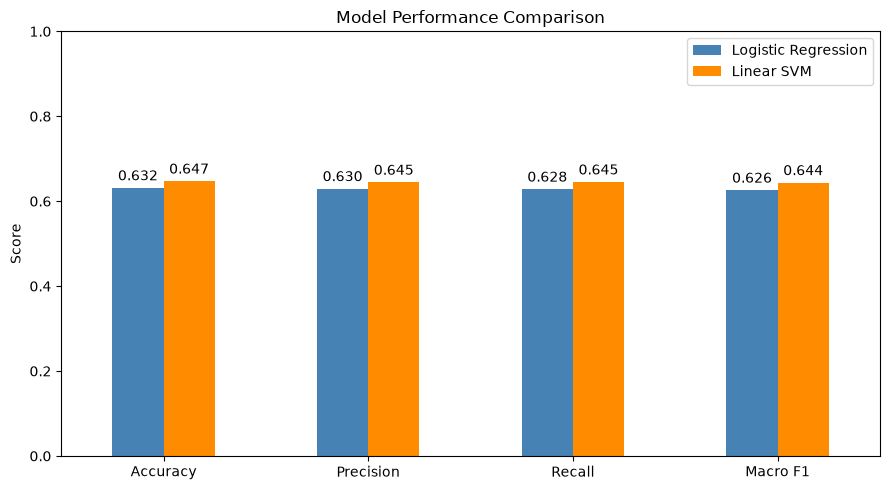

In [43]:
ax = results.T.plot(
    kind="bar",
    figsize=(9, 5),
    ylim=(0, 1),
    color=["steelblue", "darkorange"]
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", padding=3)

plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.legend(loc="upper right")
plt.tight_layout()

plt.savefig("images/model_comparison.png",
            dpi=200, bbox_inches="tight")
plt.show()

#### 성능 비교 결과 분석

실험 결과, Linear SVM이 Logistic Regression보다 모든 평가 지표에서 높은 성능을 보였다.

Linear SVM의 Accuracy는 64.73%로 Logistic Regression보다 약 1.58%p 높았으며, Macro F1-score는 0.6437로 약 0.0177 높게 나타났다.

이를 통해 동일한 데이터와 TF-IDF 설정을 적용한 실험 환경에서 Linear SVM이 상대적으로 우수한 감정 분류 성능을 보였음을 확인하였다.

### 4.3 혼동행렬 (Confusion Matrix)

혼동행렬을 이용하여 감정 클래스별 정분류 및 오분류 현황을 확인한다.
대각선은 실제 감정과 예측 감정이 일치하는 데이터의 개수를 의미하며,
나머지 영역은 다른 감정으로 잘못 분류된 데이터의 개수를 의미한다.

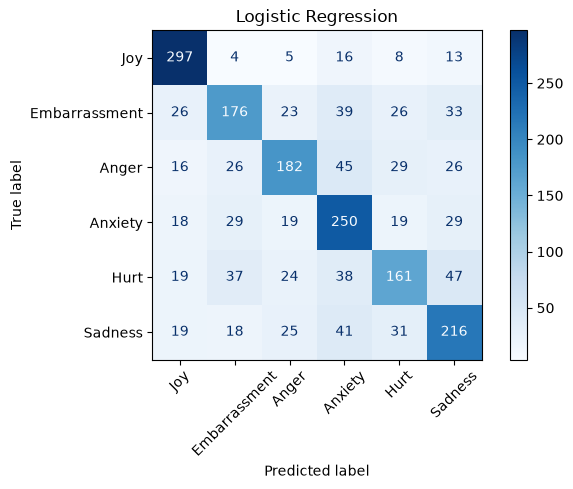

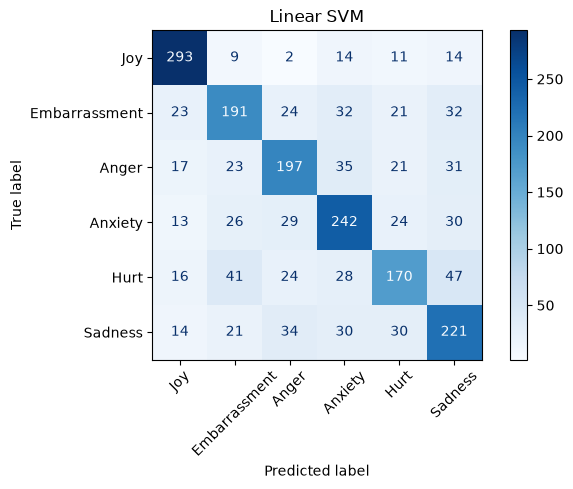

In [44]:
labels = sorted(y.unique())
display_labels = [emotion_names[label] for label in labels]

for name, pred in [
    ("Logistic Regression", lr_pred),
    ("Linear SVM", svm_pred)
]:
    fig, ax = plt.subplots(figsize=(7, 5))

    ConfusionMatrixDisplay.from_predictions(
        y_valid,
        pred,
        labels=labels,
        display_labels=display_labels,
        cmap="Blues",
        xticks_rotation=45,
        ax=ax
    )

    plt.title(name)
    plt.tight_layout()
    plt.savefig(
    f"images/confusion_matrix_{name.lower().replace(' ', '_')}.png",
    dpi=200,
    bbox_inches="tight"
    )
    plt.show()

#### 혼동행렬 결과 분석

두 모델 모두 기쁨(Joy)에 대해 85% 이상의 Recall을 보였으나, 상처(Hurt)에 대해서는 상대적으로 낮은 분류 성능을 보였다.

특히 두 모델 모두 상처를 슬픔으로 잘못 분류한 사례가 47건으로 나타났다. 이는 유사한 부정적 감정 사이에서 사용되는 단어와 표현이 겹치기 때문일 가능성이 있다.

Logistic Regression은 기쁨과 불안에서, Linear SVM은 당황, 분노, 상처, 슬픔에서 더 높은 Recall을 보였다. 이를 통해 알고리즘에 따라 감정 클래스별 분류 성능에 차이가 있음을 확인하였다.

### 4.4 실제 감정과 예측 감정 비교

검증 데이터의 실제 감정과 각 모델의 예측 감정을 비교하여
개별 발화에 대한 분류 결과를 확인한다.

별도로 제공된 Test 데이터에는 실제 감정 레이블이 없으므로,
실제값과 예측값의 비교는 학습에 사용하지 않은 검증 데이터에서 수행한다.

In [45]:
comparison = pd.DataFrame({
    "입력 문장": X_valid.values,
    "실제 감정": y_valid.values,
    "LR 예측": lr_pred,
    "SVM 예측": svm_pred,
    "LR 정분류": y_valid.values == lr_pred,
    "SVM 정분류": y_valid.values == svm_pred
})

comparison.drop(columns=["입력 문장"]).head(20)

,실제 감정,LR 예측,SVM 예측,LR 정분류,SVM 정분류
0,슬픔,상처,슬픔,False,True
1,상처,당황,당황,False,False
2,상처,상처,상처,True,True
3,슬픔,슬픔,슬픔,True,True
4,불안,불안,불안,True,True
5,상처,슬픔,슬픔,False,False
6,기쁨,기쁨,기쁨,True,True
7,기쁨,기쁨,기쁨,True,True
8,기쁨,기쁨,기쁨,True,True
9,분노,상처,상처,False,False


In [46]:
# 최종 모델 선정
best_model_name = results["Macro F1"].idxmax()

print("최종 선정 모델:", best_model_name)
print("Accuracy:", round(results.loc[best_model_name, "Accuracy"], 4))
print("Macro F1:", round(results.loc[best_model_name, "Macro F1"], 4))

최종 선정 모델: Linear SVM
Accuracy: 0.6473
Macro F1: 0.6437


## 5. 최종 모델 선정 및 저장

모든 감정 클래스의 분류 성능을 균형 있게 고려하기 위해
Macro F1-score를 최종 모델 선정 기준으로 설정하였다.

성능 비교 결과, Linear SVM이 0.6437로 가장 높은
Macro F1-score를 기록하여 최종 모델로 선정하였다.

검증용으로 분리했던 데이터를 포함하여 전체 학습 데이터
10,150개로 재학습을 수행하였다.

joblib을 이용하여 TF-IDF와 분류 모델이 포함된 Pipeline을
저장하고, 웹 서비스에서 별도의 재학습 없이 활용하도록 하였다.

In [47]:
import joblib
from pathlib import Path
from sklearn.base import clone

models = {
    "Logistic Regression": lr_model,
    "Linear SVM": svm_model
}

# 최종 모델 선정 및 전체 데이터 재학습
final_model = clone(models[best_model_name])
final_model.fit(X, y)

# 모델 저장
Path("model").mkdir(exist_ok=True)

joblib.dump(final_model, "model/emotion_classifier.pkl")

print("최종 모델:", best_model_name)
print("전체 학습 데이터:", len(X))
print("모델 저장 완료")

최종 모델: Linear SVM
전체 학습 데이터: 10150
모델 저장 완료


## 6. Test 데이터 예측

저장된 모델을 불러와 별도로 제공된 Test 데이터 1,276개의
감정을 예측한다.

Test 데이터에는 실제 감정 레이블이 제공되지 않으므로
정량적인 성능 평가는 검증 데이터에서 수행하였으며,
Test 데이터는 최종 예측 결과 생성에 활용한다.

예측 결과는 ID와 감정_대분류 컬럼으로 구성하여 CSV 파일로 저장한다.

In [48]:
# 저장된 모델 불러오기
loaded_model = joblib.load("model/emotion_classifier.pkl")

# Test 데이터 예측
test_pred = loaded_model.predict(test["text"])

submission = pd.DataFrame({
    "ID": test["ID"],
    "감정_대분류": test_pred
})

# submission.head(10)
print("Test 데이터 예측 완료")

Test 데이터 예측 완료


In [49]:
# 예측 결과 검증
print("예측 데이터 개수:", len(submission))
print("ID 중복:", submission["ID"].duplicated().sum())
print("결측치:", submission.isna().sum().sum())

display(submission["감정_대분류"].value_counts())

# 예측 결과 저장
Path("submission").mkdir(exist_ok=True)

submission.to_csv(
    "submission/submission.csv",
    index=False,
    encoding="utf-8-sig"
)

print("예측 결과 저장 완료")

예측 데이터 개수: 1276
ID 중복: 0
결측치: 0


감정_대분류
기쁨    259
슬픔    236
불안    216
분노    206
당황    191
상처    168
Name: count, dtype: int64

예측 결과 저장 완료


## 7. 웹 서비스 구현

Streamlit을 이용하여 사용자가 직접 입력한 문장의 감정을
예측하는 웹 서비스를 구현하였다.

### 구현 절차

1. joblib을 이용하여 저장된 Pipeline 모델을 불러온다.
2. 사용자로부터 발화 텍스트를 입력받는다.
3. 학습 데이터와 동일한 텍스트 정제를 수행한다.
4. Pipeline 내부에서 TF-IDF 벡터화 및 감정 분류를 수행한다.
5. 예측된 감정 클래스를 화면에 출력한다.

저장된 모델을 활용하므로 웹 서비스 실행 시
별도의 모델 재학습이 필요하지 않다.

### 실행 방법

터미널에서 프로젝트 최상위 폴더로 이동한 후
`streamlit run app.py` 명령어를 실행한다.

In [50]:
sample_texts = [
    "오늘 손주가 찾아와서 정말 행복했어요.",
    "요즘 혼자 있는 시간이 많아서 너무 외로워요.",
    "건강이 더 나빠질까 봐 걱정돼요.",
    "아무도 내 이야기를 들어주지 않아서 화가 나요."
]

sample_pred = loaded_model.predict([
    clean_text(text) for text in sample_texts
])

pd.DataFrame({
    "입력 문장": sample_texts,
    "예측 감정": sample_pred
})

,입력 문장,예측 감정
0,오늘 손주가 찾아와서 정말 행복했어요.,기쁨
1,요즘 혼자 있는 시간이 많아서 너무 외로워요.,당황
2,건강이 더 나빠질까 봐 걱정돼요.,슬픔
3,아무도 내 이야기를 들어주지 않아서 화가 나요.,분노


## 8. 결론 및 한계점

AI Hub의 노년층 감정 데이터를 활용하여 지도학습 기반 감정 분류 모델을 구현하였다. 동일한 TF-IDF 설정을 기반으로 Logistic Regression과 Linear SVM의 성능을 비교하였으며, Accuracy 64.73%, Macro F1-score 0.6437을 기록한 Linear SVM을 최종 모델로 선정하였다.

선정된 모델을 Streamlit 웹 서비스에 연동하여 사용자가 직접 입력한 문장의 감정을 예측할 수 있도록 구현하였다.

### 8.1 웹 서비스 테스트

실제 웹 서비스에 다양한 유형의 문장을 직접 입력하여 모델의 감정 분류 결과를 확인하였다.

| 테스트 유형 | 입력 문장 | 의도한 감정 | 예측 감정 |
|---|---|---|---|
| 명확한 감정 | 오늘 손주가 찾아와서 정말 행복했어요. | 기쁨 | 기쁨 |
| 간접적인 감정 | 오늘도 아무에게도 연락이 오지 않았어요. | 슬픔 | 상처 |
| 부정 표현 | 하나도 기쁘지 않아요. | 슬픔 등 | 분노 |
| 복합 감정 | 손주가 찾아와서 기뻤지만 떠나고 나니 외로워요. | 기쁨, 슬픔 | 불안 |
| 반어적 표현 | 참 잘됐네요. 평생 모은 돈을 다 잃었으니. | 분노, 슬픔 | 분노 |
| 짧은 문장 | 보고 싶어요. | 문맥에 따라 다름 | 불안 |
| 중립적인 문장 | 오늘은 수요일입니다. | 중립 | 당황 |
| 일상적 유행 표현 | 오늘 우울해서 빵 샀어. | 슬픔 | 기쁨 |

감정이 명확하게 드러나는 문장에서는 의도한 감정과 일치하는 결과가 나타났으나, 간접적인 감정 표현이나 복합적인 문장에서는 의도와 다른 예측 결과가 나타났다.

해당 테스트는 직접 작성한 문장을 활용한 정성적 평가로, 객관적인 정답 레이블을 기반으로 한 정량적 성능 평가와는 구분된다.

### 8.2 추가 실험: 감정과 행동 간의 문맥 이해

일상에서 상대방의 반응을 통해 MBTI 성향을 알아보는 유행 표현인 "오늘 우울해서 빵 샀어."를 입력해 보았다.

해당 문장은 우울한 감정으로 인해 빵을 구매했다는 의미를 담고 있지만, 모델은 이를 기쁨으로 분류하였다.

이에 대한 원인을 탐색하기 위해 감정 표현과 행동 표현을 분리하거나 일부 표현을 변경하여 추가 실험을 진행하였다.

| 입력 문장 | 예측 감정 |
|---|---|
| 오늘 우울해. | 슬픔 |
| 오늘 빵 샀어. | 기쁨 |
| 오늘 우울해서 빵 샀어. | 기쁨 |
| 오늘 기분이 좋아서 빵 샀어. | 기쁨 |
| 오늘 우울해서 빵을 샀어요. | 기쁨 |

실험 결과, 감정 표현만 입력했을 때는 슬픔으로 분류되었으나 행동 표현이 포함된 문장에서는 기쁨으로 분류되었다. 또한 행동의 원인이 되는 감정을 변경하거나 조사와 어미를 변경해도 동일한 예측 결과가 나타났다.

이는 TF-IDF 기반 모델이 감정과 행동 사이의 인과관계보다 특정 단어 및 단어 조합의 특징에 더 크게 영향을 받았을 가능성을 보여준다.

### 8.3 한계점 및 개선 방향

- **문맥 이해의 한계:** TF-IDF는 단어의 빈도와 중요도를 기반으로 하므로 문장 전체의 의미와 인과관계를 충분히 반영하기 어렵다. 향후 한국어 BERT 기반 모델을 활용하여 문맥 이해 능력을 개선할 수 있다.

- **복합 감정 처리의 한계:** 하나의 문장에 여러 감정이 포함되어 있어도 단일 감정으로만 분류한다. 다중 레이블 분류(Multi-label Classification)를 적용하여 여러 감정을 동시에 예측하도록 개선할 수 있다.

- **중립 클래스의 부재:** 감정이 없는 문장도 기존 6개 감정 클래스 중 하나로 분류된다. 중립 클래스에 해당하는 데이터를 추가하여 불필요한 감정 분류를 방지할 수 있다.

- **학습 데이터와 실제 입력의 차이:** 학습 데이터는 노년층의 여러 발화로 구성되어 있으므로 짧은 문장이나 다양한 연령층의 일상 표현에 대한 일반화 성능에는 한계가 있을 수 있다. 다양한 발화 형태와 표현을 포함한 데이터를 확보하여 개선할 수 있다.

본 프로젝트를 통해 감정 분류에서는 단순히 감정 관련 단어를 인식하는 것뿐만 아니라 문장 전체의 의미와 맥락을 이해하는 것이 중요하다는 점을 확인하였다.

In [51]:
print("===== 최종 프로젝트 결과 =====")
print("최종 모델:", best_model_name)
print("전체 학습 데이터:", len(X))
print("검증 데이터:", len(X_valid))
print("Test 예측 데이터:", len(submission))

display(results.loc[[best_model_name]].round(4))

===== 최종 프로젝트 결과 =====
최종 모델: Linear SVM
전체 학습 데이터: 10150
검증 데이터: 2030
Test 예측 데이터: 1276


,Accuracy,Precision,Recall,Macro F1
Linear SVM,0.6473,0.6445,0.6452,0.6437
